# Lab 13: Carryover, Lag and Adstock

This lab shows how geometric adstock spreads a media impulse over time and reshapes a bursty spend series into a smoother, carried-over response.
It accompanies Chapter 13 of the book Marketing Mix Modelling.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from mmm_book import RANDOM_SEED
from mmm_book.adstock import geometric_adstock
from mmm_book.plotting import mmm_style

mmm_style()
rng = np.random.default_rng(RANDOM_SEED)

## The book's worked example, in two conventions

Chapter 13 spends £100,000 on television in week 1 and nothing afterwards, with alpha = 0.5.
The book's table (£100,000, £50,000, £25,000, £12,500) uses the plain recursion `A_t = x_t + alpha * A_(t-1)`, which is `normalize=False` in `geometric_adstock`.
The labs and the Sedge Shoes generator use `normalize=True`, which rescales the lag weights to sum to one so that a steady spend level maps to itself.
pymc-marketing's `GeometricAdstock` component normalises by default as well (its low-level function does not), so it is worth knowing which convention you are looking at.
The two columns differ only by a constant factor, so the shape of the carryover is the same.

In [2]:
one_burst = np.array([100_000.0, 0.0, 0.0, 0.0])

book_convention = geometric_adstock(one_burst, alpha=0.5, l_max=4, normalize=False)
normalised = geometric_adstock(one_burst, alpha=0.5, l_max=12, normalize=True)

print("week   book (raw)   normalised (l_max=12)")
for week, (b, n) in enumerate(zip(book_convention, normalised, strict=True), start=1):
    print(f"{week:>4}   {b:>10,.0f}   {n:>10,.0f}")

# The book prints 100,000 / 50,000 / 25,000 / 12,500.
np.testing.assert_allclose(book_convention, [100_000, 50_000, 25_000, 12_500])

week   book (raw)   normalised (l_max=12)
   1      100,000       50,012
   2       50,000       25,006
   3       25,000       12,503
   4       12,500        6,252


## Impulse response

A unit of spend in a single period does not just affect that period.
Geometric adstock carries some of its effect into future periods, with the rate of decay controlled by the retention rate `alpha` ($\alpha$ in the book).
The plot below shows the impulse response for a few values of `alpha`.

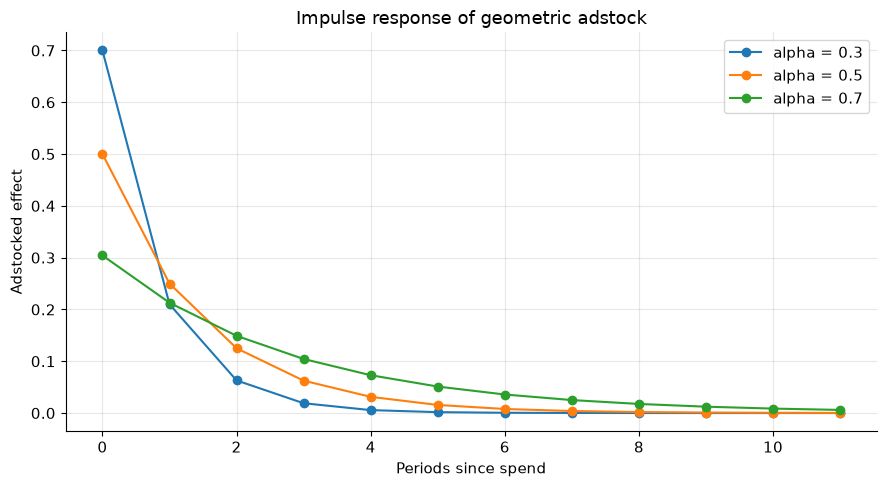

In [3]:
l_max = 12
impulse = np.zeros(l_max)
impulse[0] = 1.0

alphas = [0.3, 0.5, 0.7]

fig, ax = plt.subplots()
for alpha in alphas:
    response = geometric_adstock(impulse, alpha=alpha, l_max=l_max, normalize=True)
    ax.plot(response, marker="o", label=f"alpha = {alpha}")

ax.set_xlabel("Periods since spend")
ax.set_ylabel("Adstocked effect")
ax.set_title("Impulse response of geometric adstock")
ax.legend()
fig.tight_layout()

## Adstock applied to a bursty spend series

Real media spend is rarely a single impulse.
It tends to arrive in bursts, for example a short flight of TV activity.
Adstock smooths these bursts and extends their influence past the weeks in which spend actually happened.

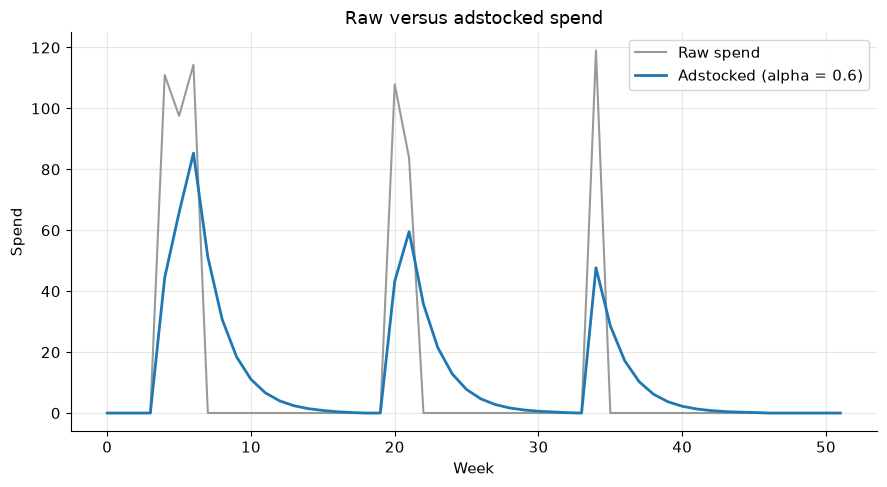

In [4]:
n_weeks = 52
spend = np.zeros(n_weeks)
burst_weeks = [4, 5, 6, 20, 21, 34]
spend[burst_weeks] = rng.uniform(80, 120, size=len(burst_weeks))

alpha = 0.6
adstocked = geometric_adstock(spend, alpha=alpha, l_max=12, normalize=True)

fig, ax = plt.subplots()
ax.plot(spend, label="Raw spend", color="0.6", linewidth=1.5)
ax.plot(adstocked, label=f"Adstocked (alpha = {alpha})", linewidth=2)
ax.set_xlabel("Week")
ax.set_ylabel("Spend")
ax.set_title("Raw versus adstocked spend")
ax.legend()
fig.tight_layout()

## Takeaway

Adstock is a simple but important idea: media effects persist beyond the period in which the spend happened.
The retention rate `alpha` ($\alpha$) controls how quickly that persistence fades, and normalising the lag weights keeps the total adstocked effect on the same scale as the raw spend.
Later chapters build on this transform as one stage of the full media response function, alongside saturation.